In [170]:
import pandas as pd
df= pd.read_csv('uber.csv')

In [171]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [172]:
df.drop(['key', 'Unnamed: 0'], axis=1, inplace=True)
df.dropna(inplace=True)

In [173]:
df= df[df["fare_amount"]>0]

In [174]:
df= df[df["pickup_longitude"].between(-180, 180) & df["dropoff_longitude"].between(-180, 180) & df["pickup_latitude"].between(-90,90) & df["dropoff_latitude"].between(-90,90)]

In [175]:
df= df[df["passenger_count"].between(0,6)]

In [176]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

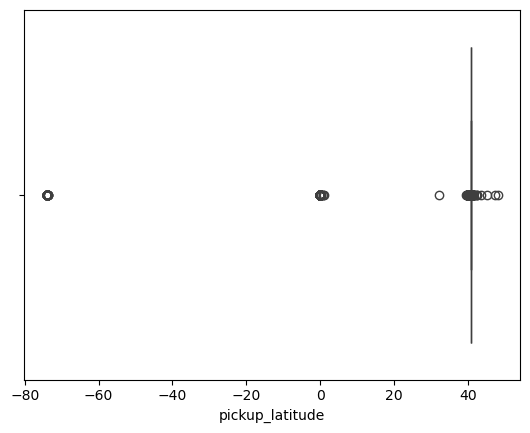

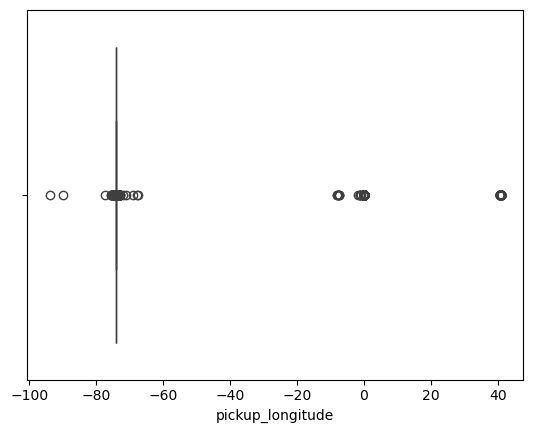

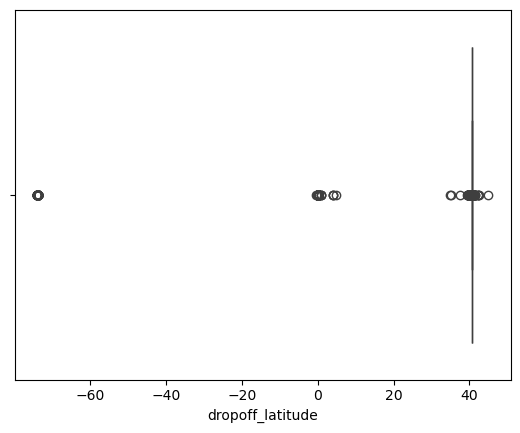

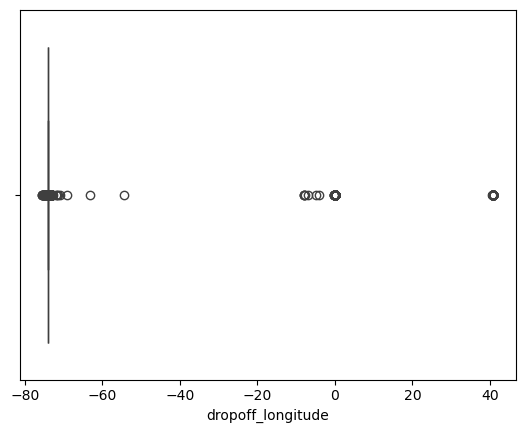

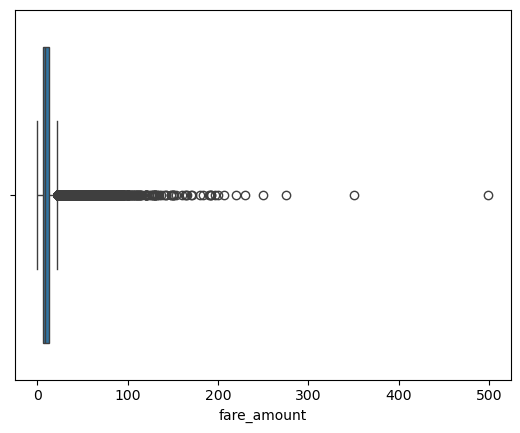

In [177]:
import matplotlib.pyplot as plt 
import seaborn as sns
feature=["pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude", "fare_amount"]
for f in feature:
    sns.boxplot(x=df[f])
    plt.show()

In [178]:
def remove_outliers(df, feature):
    q1= df[feature].quantile(0.25)
    q3= df[feature].quantile(0.75)
    iqr= q3-q1
    lower= q1-(1.5*iqr)
    upper = q3+ (1.5*iqr)
    df= df[(df[feature]<=upper) & (df[feature]>=lower)]
    return df

In [179]:
feature=["pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude", "fare_amount"]
for f in feature:
    df = remove_outliers(df, f)
    

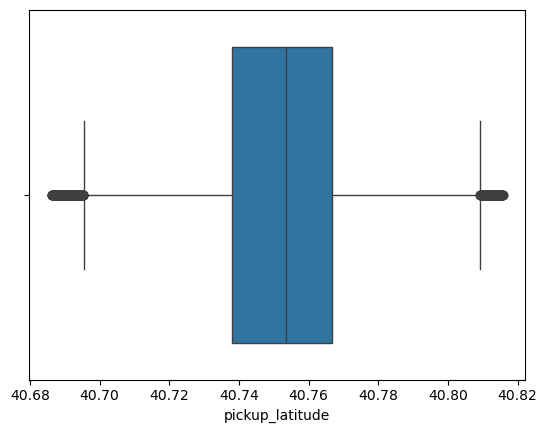

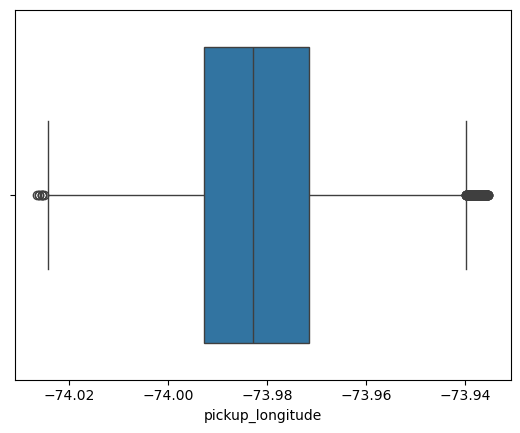

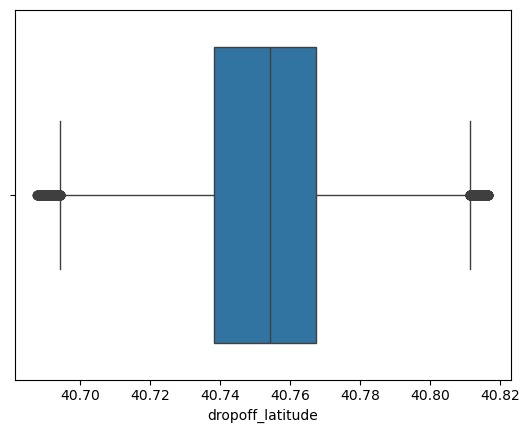

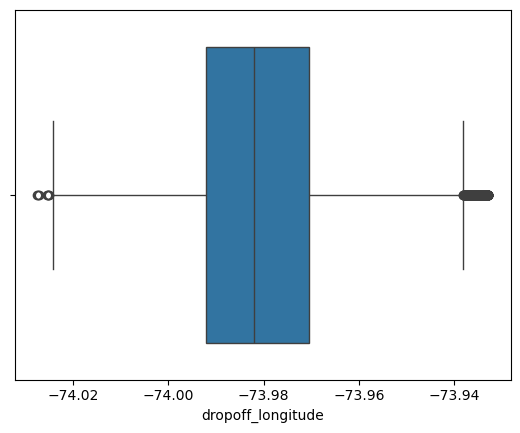

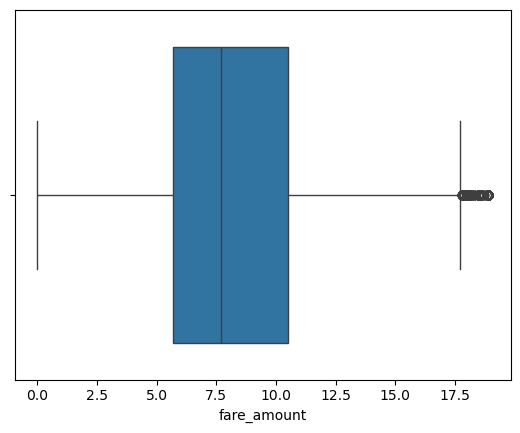

In [180]:
import matplotlib.pyplot as plt 
import seaborn as sns
feature=["pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude", "fare_amount"]
for f in feature:
    sns.boxplot(x=df[f])
    plt.show()

In [181]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
5,4.9,2011-02-12 02:27:09 UTC,-73.969019,40.755910,-73.969019,40.755910,1


In [182]:
import numpy as np
def eu(pickup_longitude, pickup_latitude, dropoff_longitude, dropoff_latitude):
    d1= dropoff_longitude- pickup_longitude
    d2= dropoff_latitude- pickup_latitude
    dist= np.sqrt(d1**2 +d2**2)
    return dist

In [183]:
distances=[]
for i in range(len(df)):
    dist= eu(df["pickup_longitude"].iloc[i], df["pickup_latitude"].iloc[i], df["dropoff_longitude"].iloc[i], df["dropoff_latitude"].iloc[i])
    distances.append(dist)
df["distance"]=distances

In [184]:
df.drop(["pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"], axis=1, inplace=True)

In [185]:
df.head()

,fare_amount,pickup_datetime,passenger_count,distance
0,7.5,2015-05-07 19:52:06 UTC,1,0.015140
1,7.7,2009-07-17 20:04:56 UTC,1,0.022103
2,12.9,2009-08-24 21:45:00 UTC,1,0.053109
3,5.3,2009-06-26 08:22:21 UTC,3,0.016528
5,4.9,2011-02-12 02:27:09 UTC,1,0.000000


In [186]:
df["pickup_datetime"]=pd.to_datetime(df["pickup_datetime"],utc=True)

In [187]:
df["hour"]= df["pickup_datetime"].dt.hour

In [188]:
df.drop(["pickup_datetime"], axis=1, inplace=True)

<Axes: >

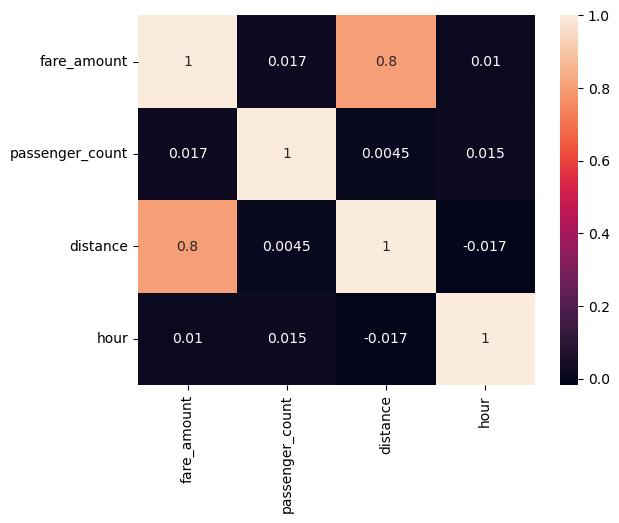

In [206]:
corr= df.corr(method='pearson')
sns.heatmap(corr, annot=True)

In [190]:
y= df["fare_amount"]
X=df.drop(["fare_amount"], axis=1)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=0.20, random_state=42)

In [192]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

In [195]:
from sklearn.linear_model import LinearRegression
model= LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred= model.predict(X_test_scaled)

In [200]:
from sklearn.ensemble import RandomForestRegressor
model= RandomForestRegressor(random_state=42, max_depth=5, n_estimators=100)
model.fit(X_train_scaled, y_train)
y_pred_rf=model.predict(X_test_scaled)

In [203]:
from sklearn.metrics import (r2_score, mean_squared_error)
print(r2_score(y_test, y_pred))
print(np.sqrt(mean_squared_error(y_test, y_pred)))


0.6357838788458241
2.1207978849873723


In [204]:
from sklearn.metrics import (r2_score, mean_squared_error)
print(r2_score(y_test, y_pred_rf))
print(np.sqrt(mean_squared_error(y_test, y_pred_rf)))


0.6624540929801711
2.0416727027620714
